In [23]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import os

DATA_PATH = "../data/student_performance_dataset.csv"

print("Dataset exists:", os.path.exists(DATA_PATH))

Dataset exists: True


In [5]:
df = pd.read_csv(DATA_PATH, sep=";")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully.
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [6]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

print("\nFirst five records:")
display(df.head())

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    st

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [7]:
df = df.drop_duplicates()

df = df.dropna(
    subset=["G3"]
)

df = df.reset_index(drop=True)

print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (395, 33)


In [8]:
df["StudyHours"] = df["studytime"]

df["PreviousMarks"] = df["G1"]

df["FinalMarks"] = df["G3"]

df["PreviousMarks"] = df["PreviousMarks"].astype(float)

df["FinalMarks"] = df["FinalMarks"].astype(float)

df["StudyHours"] = df["StudyHours"].astype(float)

df["Absences"] = df["absences"]

df["Passed"] = np.where(
    df["FinalMarks"] >= 10,
    1,
    0
)

df[[
    "StudyHours",
    "PreviousMarks",
    "Absences",
    "FinalMarks",
    "Passed"
]].head()

,StudyHours,PreviousMarks,Absences,FinalMarks,Passed
0,2.0,5.0,6,6.0,0
1,2.0,5.0,4,6.0,0
2,2.0,7.0,10,10.0,1
3,3.0,15.0,2,15.0,1
4,2.0,6.0,4,10.0,1


In [9]:
print("Mean:")
display(df.mean(numeric_only=True))

print("\nMedian:")
display(df.median(numeric_only=True))

print("\nStandard deviation:")
display(df.std(numeric_only=True))

print("\nSummary statistics:")
display(df.describe())

Mean:


age              16.696203
Medu              2.749367
Fedu              2.521519
traveltime        1.448101
studytime         2.035443
failures          0.334177
famrel            3.944304
freetime          3.235443
goout             3.108861
Dalc              1.481013
Walc              2.291139
health            3.554430
absences          5.708861
G1               10.908861
G2               10.713924
G3               10.415190
StudyHours        2.035443
PreviousMarks    10.908861
FinalMarks       10.415190
Absences          5.708861
Passed            0.670886
dtype: float64


Median:


age              17.0
Medu              3.0
Fedu              2.0
traveltime        1.0
studytime         2.0
failures          0.0
famrel            4.0
freetime          3.0
goout             3.0
Dalc              1.0
Walc              2.0
health            4.0
absences          4.0
G1               11.0
G2               11.0
G3               11.0
StudyHours        2.0
PreviousMarks    11.0
FinalMarks       11.0
Absences          4.0
Passed            1.0
dtype: float64


Standard deviation:


age              1.276043
Medu             1.094735
Fedu             1.088201
traveltime       0.697505
studytime        0.839240
failures         0.743651
famrel           0.896659
freetime         0.998862
goout            1.113278
Dalc             0.890741
Walc             1.287897
health           1.390303
absences         8.003096
G1               3.319195
G2               3.761505
G3               4.581443
StudyHours       0.839240
PreviousMarks    3.319195
FinalMarks       4.581443
Absences         8.003096
Passed           0.470487
dtype: float64


Summary statistics:


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,health,absences,G1,G2,G3,StudyHours,PreviousMarks,FinalMarks,Absences,Passed
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,...,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,...,3.554430,5.708861,10.908861,10.713924,10.415190,2.035443,10.908861,10.415190,5.708861,0.670886
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,...,1.390303,8.003096,3.319195,3.761505,4.581443,0.839240,3.319195,4.581443,8.003096,0.470487
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,0.000000,3.000000,0.000000,0.000000,1.000000,3.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,...,3.000000,0.000000,8.000000,9.000000,8.000000,1.000000,8.000000,8.000000,0.000000,0.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,...,4.000000,4.000000,11.000000,11.000000,11.000000,2.000000,11.000000,11.000000,4.000000,1.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,...,5.000000,8.000000,13.000000,13.000000,14.000000,2.000000,13.000000,14.000000,8.000000,1.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,75.000000,19.000000,19.000000,20.000000,4.000000,19.000000,20.000000,75.000000,1.000000


In [11]:
import os

VISUALIZATION_DIR = "../outputs/visualizations"

os.makedirs(VISUALIZATION_DIR, exist_ok=True)

print("Visualization folder is ready!")

Visualization folder is ready!


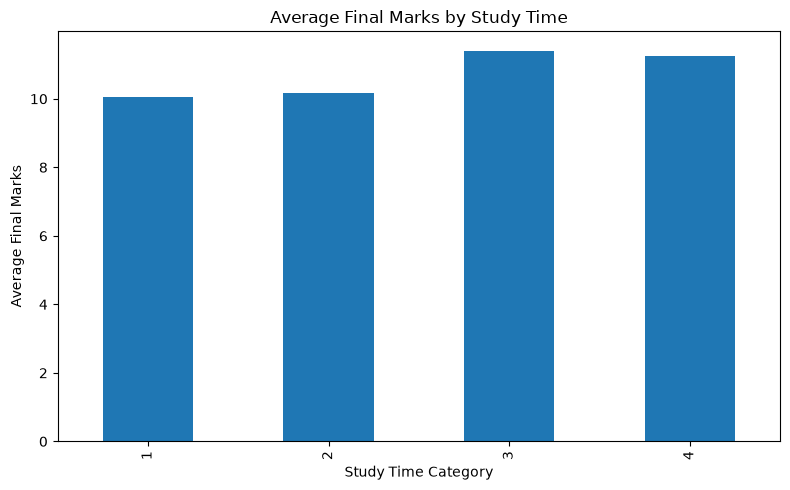

In [12]:
plt.figure(figsize=(8, 5))

df.groupby("studytime")["G3"].mean().plot(
    kind="bar"
)

plt.title("Average Final Marks by Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Average Final Marks")
plt.tight_layout()

plt.savefig(
    os.path.join(
        VISUALIZATION_DIR,
        "study_time_bar_chart.png"
    )
)

plt.show()

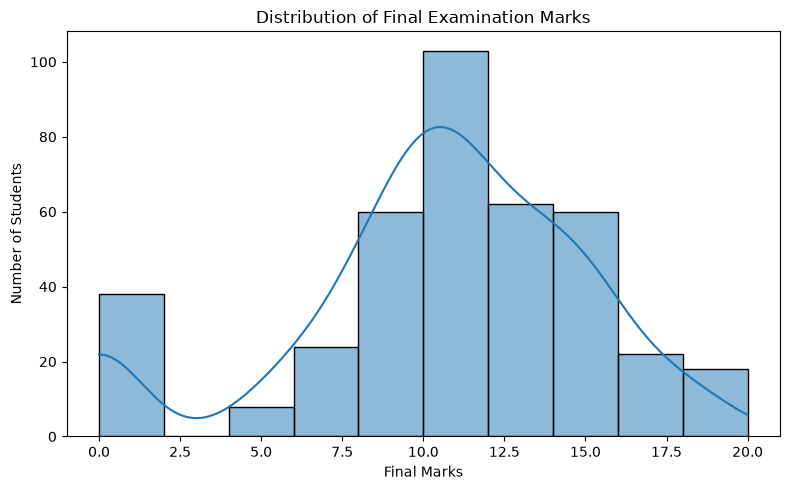

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["FinalMarks"],
    bins=10,
    kde=True
)

plt.title("Distribution of Final Examination Marks")
plt.xlabel("Final Marks")
plt.ylabel("Number of Students")
plt.tight_layout()

plt.savefig(
    os.path.join(
        VISUALIZATION_DIR,
        "final_marks_histogram.png"
    )
)

plt.show()

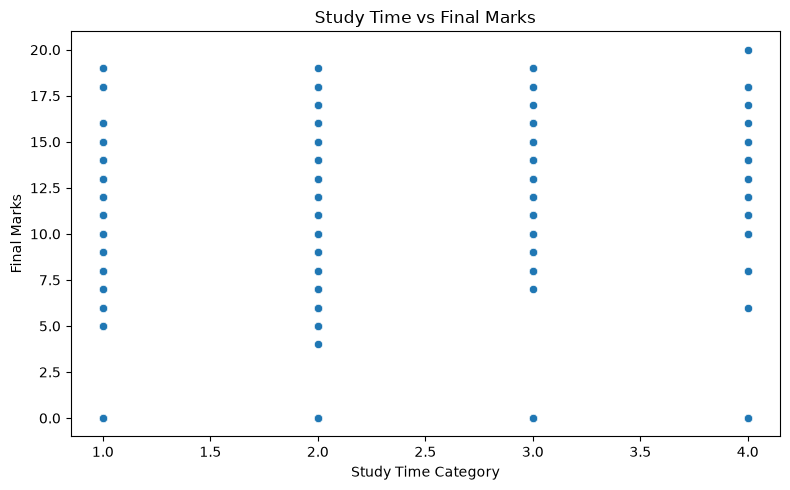

In [14]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="StudyHours",
    y="FinalMarks"
)

plt.title("Study Time vs Final Marks")
plt.xlabel("Study Time Category")
plt.ylabel("Final Marks")
plt.tight_layout()

plt.savefig(
    os.path.join(
        VISUALIZATION_DIR,
        "study_time_scatter_plot.png"
    )
)

plt.show()

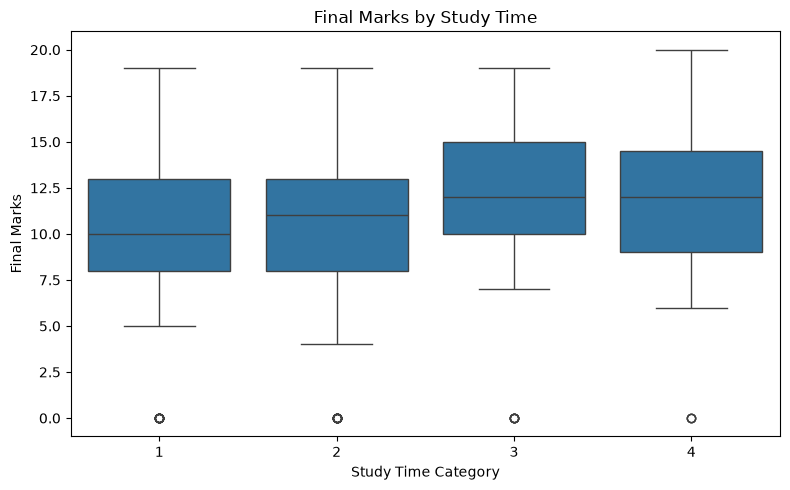

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="studytime",
    y="FinalMarks"
)

plt.title("Final Marks by Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Final Marks")
plt.tight_layout()

plt.savefig(
    os.path.join(
        VISUALIZATION_DIR,
        "study_time_box_plot.png"
    )
)

plt.show()

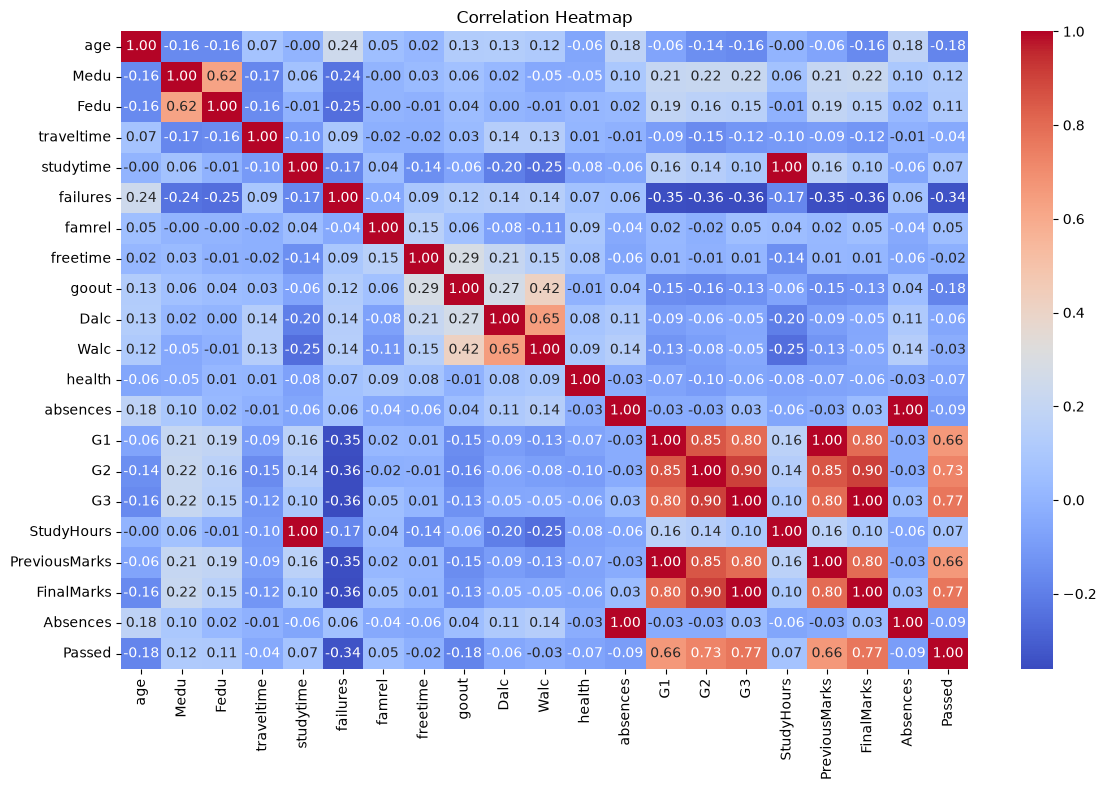

In [16]:
numeric_df = df.select_dtypes(
    include=["number"]
)

correlation = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.savefig(
    os.path.join(
        VISUALIZATION_DIR,
        "correlation_heatmap.png"
    )
)

plt.show()

In [17]:
features = [
    "studytime",
    "G1",
    "G2",
    "absences"
]

target = "G3"

X = df[features]

y = df[target]

print("Input features:")
print(features)

print("\nTarget variable:")
print(target)

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

Input features:
['studytime', 'G1', 'G2', 'absences']

Target variable:
G3

Input shape: (395, 4)
Target shape: (395,)


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (316, 4)
Testing data: (79, 4)


In [19]:
model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "regressor",
        LinearRegression()
    )
])

model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [20]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Marks": y_test.values,
    "Predicted Marks": y_pred
})

display(results.head(10))

,Actual Marks,Predicted Marks
0,10,7.103031
1,12,12.109229
2,5,3.479554
3,10,8.281773
4,9,8.562709
5,13,12.610665
6,18,18.814522
7,6,6.844699
8,0,6.980266
9,14,12.522121


In [21]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Absolute Error:", round(mae, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Model Evaluation Results
------------------------
Mean Absolute Error: 1.31
Root Mean Squared Error: 2.04
R2 Score: 0.7962


In [24]:
cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="r2"
)

print("Cross-validation R2 scores:", cv_scores)

print(
    "Average cross-validation R2:",
    round(cv_scores.mean(), 4)
)

Cross-validation R2 scores: [0.82530456 0.85638135 0.86662563 0.80638497 0.7911458 ]
Average cross-validation R2: 0.8292


In [25]:
param_grid = {
    "regressor__fit_intercept": [True, False]
}

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring="r2"
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("Best parameters:")
print(grid_search.best_params_)

print(
    "Best cross-validation R2:",
    round(grid_search.best_score_, 4)
)

Best parameters:
{'regressor__fit_intercept': True}
Best cross-validation R2: 0.8292


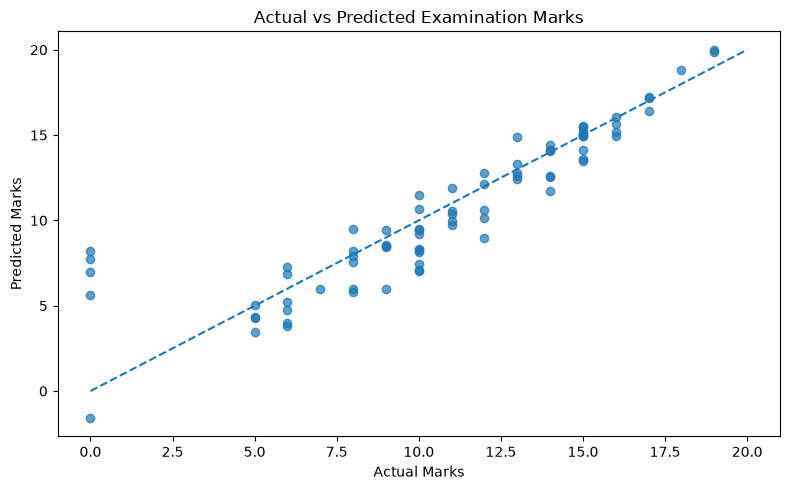

In [26]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

plt.plot(
    [0, 20],
    [0, 20],
    linestyle="--"
)

plt.title("Actual vs Predicted Examination Marks")
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.tight_layout()

plt.savefig(
    os.path.join(
        VISUALIZATION_DIR,
        "actual_vs_predicted.png"
    )
)

plt.show()

In [28]:
import os

OUTPUT_DIR = "../outputs"

EVALUATION_DIR = os.path.join(
    OUTPUT_DIR,
    "evaluation_results"
)

os.makedirs(EVALUATION_DIR, exist_ok=True)

print("Evaluation folder is ready!")

Evaluation folder is ready!


In [29]:
evaluation_results = pd.DataFrame({
    "Metric": [
        "MAE",
        "RMSE",
        "R2 Score",
        "Average Cross Validation R2"
    ],
    "Value": [
        mae,
        rmse,
        r2,
        cv_scores.mean()
    ]
})

evaluation_results.to_csv(
    os.path.join(
        EVALUATION_DIR,
        "model_evaluation_results.csv"
    ),
    index=False
)

results.to_csv(
    os.path.join(
        EVALUATION_DIR,
        "actual_vs_predicted.csv"
    ),
    index=False
)

display(evaluation_results)

,Metric,Value
0,MAE,1.312575
1,RMSE,2.044254
2,R2 Score,0.796198
3,Average Cross Validation R2,0.829168
